# Exploration: what changed between the 2023 and 2024 seasons?

This notebook is the first look at the cleaned ball-by-ball data (`data/dpl_prelims_clean.parquet`, built by `data_validation.ipynb`). It asks, in order: are the two seasons comparable at all; how did scoring change at the innings level and where in the innings; what was bowled; where did the runs go and which shots were played; and which teams moved with the league. It closes with a supplementary source, Cricsheet's match files, from which the impact-substitute deployments are extracted for the one analysis that needs them. `IPL_Auction_2023_24.xlsx` are read by the two notebooks that use them.

**How to read this notebook.** Every section states the question, runs the exploration (code in `scripts/exploration/`), and records what was found in plain terms. These are descriptive reads, not tests: they show the size and direction of each change and set up the questions the analysis notebooks answer with intervals. Two conventions used throughout: full 120-ball innings only, so rates compare like for like; and *rates* rather than counts, because the seasons have slightly different numbers of matches (74 and 71). A *powerplay* is overs 1 to 6, when fielding restrictions apply; the *middle* is overs 7 to 15; the *death* is overs 16 to 20.

**What each section hands to the analyses.** The scoring picture and phase structure motivate the season contrasts and the shape question; the tail of the totals motivates the first-innings tail analysis; the bowling section motivates the pace-share themes; the team attribution motivates the dispersion question; the Cricsheet supplement provides the impact-substitute table.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from exploration import season_comparability as comparability
from exploration import scoring_picture as scoring
from exploration import phase_and_bowling as phases
from exploration import shots_and_teams as shots
from exploration import cricsheet_archive as cricsheet
from exploration import impact_players as impact

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "exploration"
SEED = settings.seed("global")
PRODUCER = "exploration.ipynb"
EXTRA = {"full_innings_only": True}
df = pd.read_parquet(settings.data_path("cleaned_dataset"))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}  seasons={sorted(df['year'].unique())}")

rows=34,967  matches=145  seasons=[np.int64(2023), np.int64(2024)]


## Are the two seasons comparable?

Before comparing scoring, check that the seasons have the same shape: the same ten teams with similar match loads, the same host country and a similar set of grounds, a similar toss-and-bat-first split, few no-results, and few rain-reduced innings. Any of these differing would be a competing explanation for a change in scoring.

In [2]:
groundwork = comparability.comparability_groundwork(df)
results_io.write_table(groundwork["volume"].reset_index(), settings, ANALYSIS, "season_volume", SEED, PRODUCER, EXTRA)

=== Match and innings volume ===
      matches  innings  deliveries
year                              
2023       74      147       17864
2024       71      142       17103

=== Teams and matches per team ===
      distinct_teams  mean  min  max
year                                
2023              10  14.7   14   17
2024              10  14.2   12   16

=== Venue and host-country mix ===
Distinct grounds per season:
year
2023    12
2024    13

Distinct host countries per season:
year
2023    1
2024    1

=== Toss and bat-first split ===
Fraction where toss-winner batted first:
year
2023    0.284
2024    0.268

=== Match result types ===
result_type  completed  no_result
year                             
2023                73          1
2024                71          0

=== Innings length (reduced-overs prevalence) ===
Fraction of innings reduced (<120 balls):
year
2023    0.007
2024    0.014


PosixPath('/Users/madkad/dpl_2026_s1/outputs/exploration/season_volume.csv')

Found: the same ten teams, one host country, twelve grounds in 2023 and thirteen in 2024, a stable split of about 27% of toss winners batting first, one no-result in 2023 and none in 2024, and rain-reduced innings at 0.7% and 1.4%. The seasons are structurally alike, so season differences in scoring and tactics can be read as on-field change rather than fixture shape. Absolute counts differ slightly (74 and 71 matches), which is why everything below is a rate.

## The scoring picture at innings level

One row per full innings: total, run rate (runs per six legal balls), boundary share, dot share and wickets, summarised by season as a distribution (mean, spread, 10th, 50th and 90th percentiles) rather than a mean alone, because a change can live in the tail while the average barely moves. The tail is read directly as the share of innings at or above 180, 200 and 220.

=== Distribution summary by season (shape, not just mean) ===

total:
         mean     std    p10    p50    p90
year                                      
2023  174.589  32.100  130.5  178.0  214.0
2024  183.314  36.396  141.0  180.0  224.7
  fraction of innings >= 180: {2023: np.float64(0.466), 2024: np.float64(0.507)}
  fraction of innings >= 200: {2023: np.float64(0.247), 2024: np.float64(0.293)}
  fraction of innings >= 220: {2023: np.float64(0.048), 2024: np.float64(0.143)}

run_rate:
       mean    std    p10    p50     p90
year                                    
2023  8.970  1.532  6.775  9.012  10.875
2024  9.604  1.860  7.345  9.452  12.005

boundary_pct:
       mean    std    p10    p50    p90
year                                   
2023  0.193  0.051  0.126  0.192  0.254
2024  0.213  0.064  0.143  0.208  0.292

dot_pct:
       mean    std    p10    p50    p90
year                                   
2023  0.342  0.074  0.258  0.335  0.429
2024  0.329  0.070  0.245  0.326  0

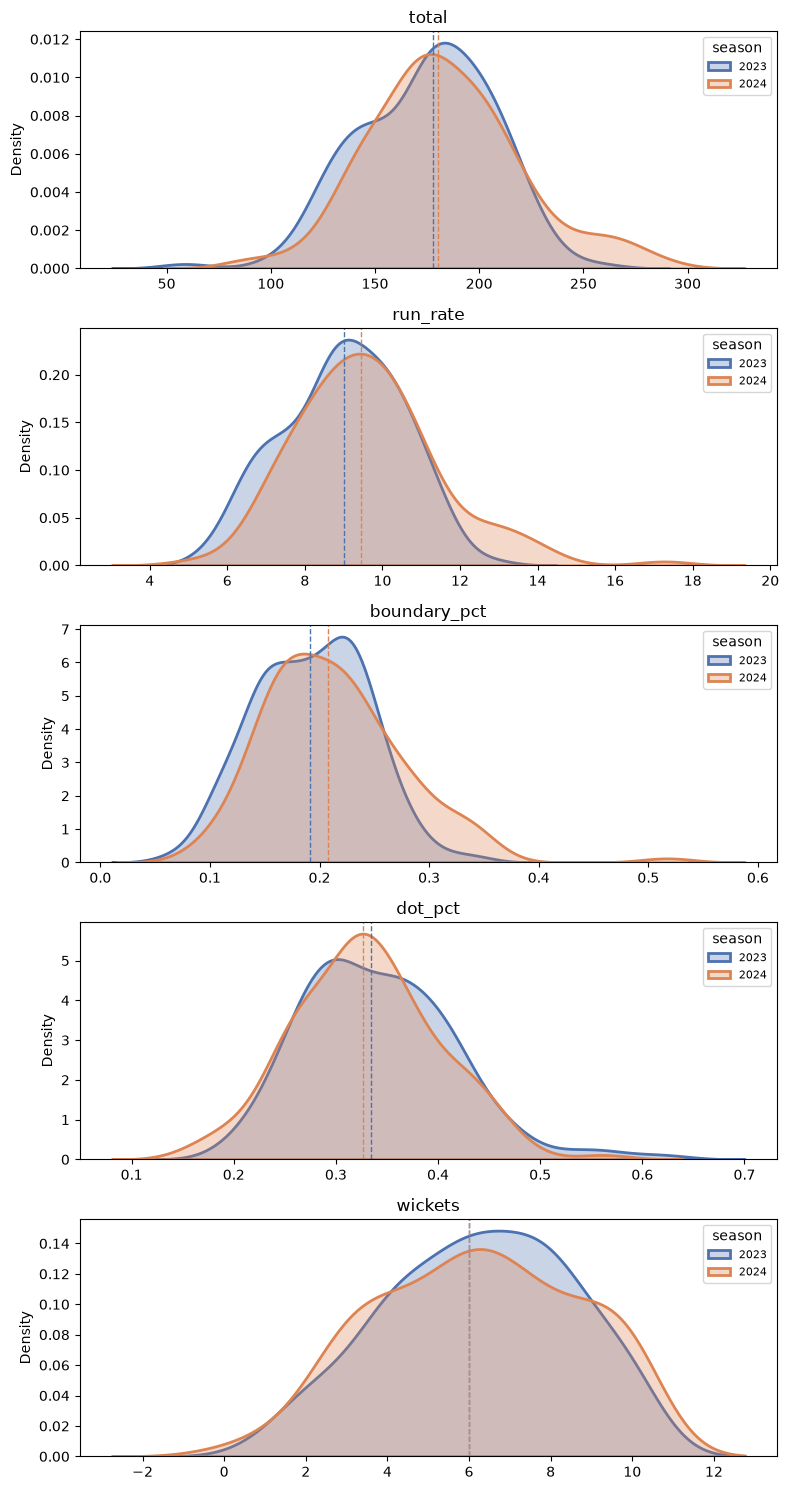

In [3]:
innings = scoring.macro_scoring_picture(df)
results_io.write_table(innings, settings, ANALYSIS, "innings_summary", SEED, PRODUCER, EXTRA)
fig = scoring.overlaid_distributions(innings)
results_io.write_figure(fig, settings, ANALYSIS, "innings_distributions", SEED, PRODUCER)
plt.show()

Found: the mean total rose from 175 to 183 and the run rate from 8.97 to 9.60. The change is not a uniform shift. The 90th percentile of totals moved by 11 runs against 2 at the median, and the share of innings at 220 or more went from 4.8% (about one in twenty) to 14.3% (about one in seven), while the 180 and 200 thresholds moved only a few points. Boundary share rose two points at the mean and nearly four at the 90th percentile; the dot share barely moved; wickets per innings were flat at a median of six. The reading is that the extra runs came from boundaries, at no visible cost in wickets, and were concentrated in the highest-scoring innings.

Hands to the analyses: the 220+ share and the upper quantiles are the question for the tail analysis, where the point is that a chasing innings stops at the target and so cannot be compared on totals with a first innings.

## Was the tail rise a venue effect?

If a few high-scoring grounds hosted more matches in 2024, the tail would rise with no change in how teams played. Two reads: how many grounds produced a 220+ innings each season, and whether the share of innings hosted by each ground shifted.

High-scoring innings (>= 220) by ground and season:

                                                                      innings      high(>=220)      high_rate       
year                                                                     2023 2024        2023 2024      2023   2024
ground                                                                                                              
Arun Jaitley Stadium, Delhi                                                14   10         1.0  6.0     0.071  0.600
Eden Gardens, Kolkata                                                      14   12         2.0  5.0     0.143  0.417
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam          0    4         0.0  1.0     0.000  0.250
Himachal Pradesh Cricket Association Stadium, Dharamsala                    4    4         0.0  1.0     0.000  0.250
Rajiv Gandhi International Stadium, Uppal, Hyderabad                       14   12         0.0  2.0     0.000  0.167
M Chinnaswa

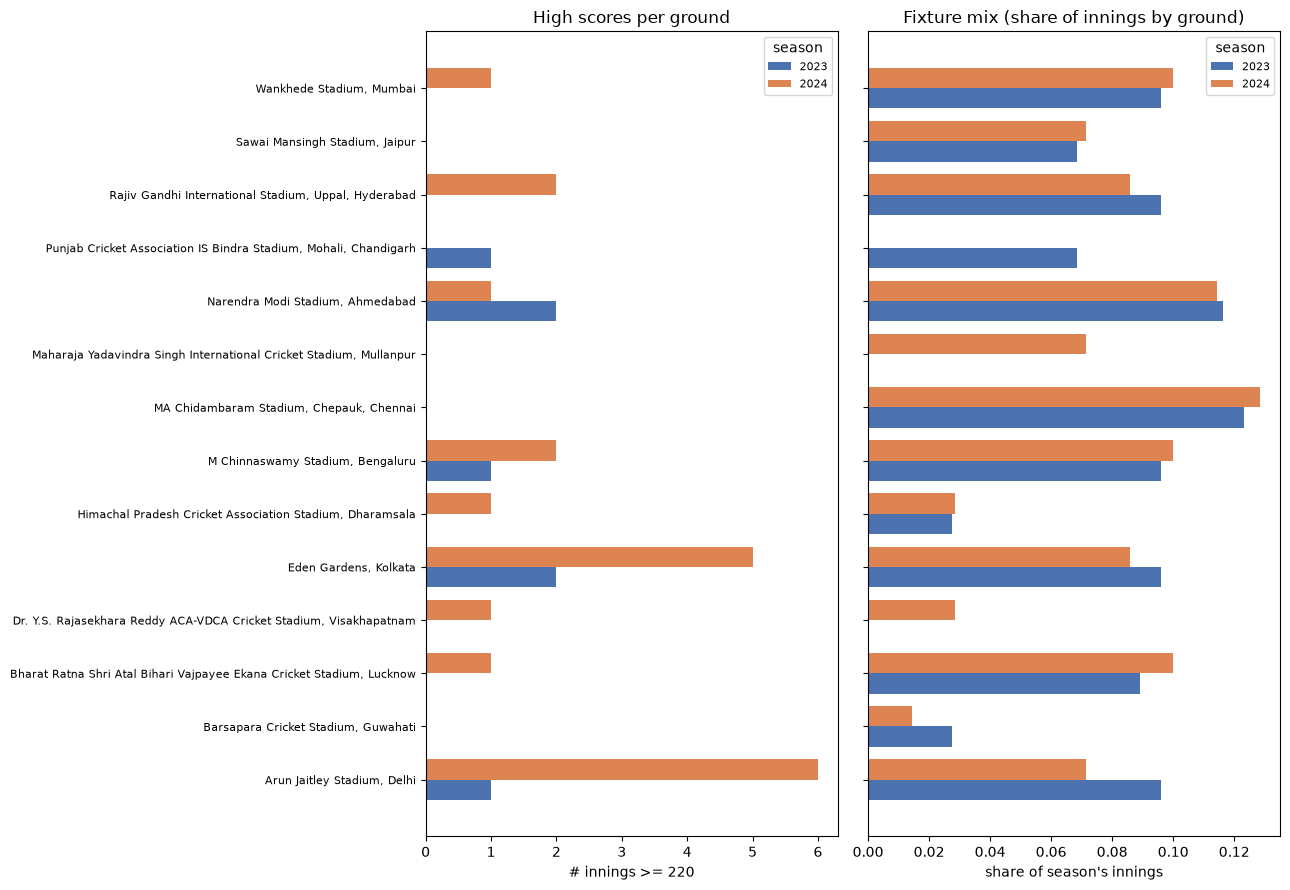

In [4]:
innings_with_ground, high_by_ground, innings_by_ground, high_rate = scoring.venue_tail_check(innings, df)
results_io.write_table(high_rate.reset_index(), settings, ANALYSIS, "venue_high_score_rate", SEED, PRODUCER, EXTRA)
fig = scoring.plot_venue_tail(high_by_ground, innings_by_ground)
results_io.write_figure(fig, settings, ANALYSIS, "venue_tail_check", SEED, PRODUCER)
plt.show()

Found: 220+ innings appeared at almost twice as many grounds in 2024 as in 2023, and the fixture mix did not tilt toward known high-scoring venues; the one new ground (Mullanpur) produced no 220+ innings in ten. Two grounds, Delhi and Kolkata, jumped far more than the rest (high-score rates of 7% to 60% and 14% to 42%) and account for eleven of the twenty 220+ innings, so the surge was broad but amplified at two venues. A venue control is worth keeping in mind for any tail claim; it is not the explanation.

## Where in the innings did the scoring move?

Per phase and season: run rate, boundary share, six share, dot share and wicket rate per legal ball, pooling every delivery in the phase (thousands of balls per phase-season, so these are precise). Then the season-over-season change per phase.

=== Per-phase batting rates by season ===

                legal_balls  run_rate  boundary_pct  six_pct  dot_pct  wicket_rate
phase     year                                                                    
powerplay 2023       5256.0     8.693         0.227    0.046    0.441        0.041
          2024       5040.0     9.462         0.250    0.064    0.419        0.044
middle    2023       7839.0     8.405         0.156    0.061    0.300        0.047
          2024       7448.0     8.820         0.167    0.069    0.291        0.047
death     2023       3947.0    10.480         0.219    0.100    0.286        0.084
          2024       3619.0    11.219         0.245    0.112    0.280        0.081

=== Change (2024 - 2023) by phase ===

run_rate:
year         2023    2024  delta
phase                           
powerplay   8.693   9.462  0.769
middle      8.405   8.820  0.415
death      10.480  11.219  0.739

boundary_pct:
year        2023   2024  delta
phase                         
p

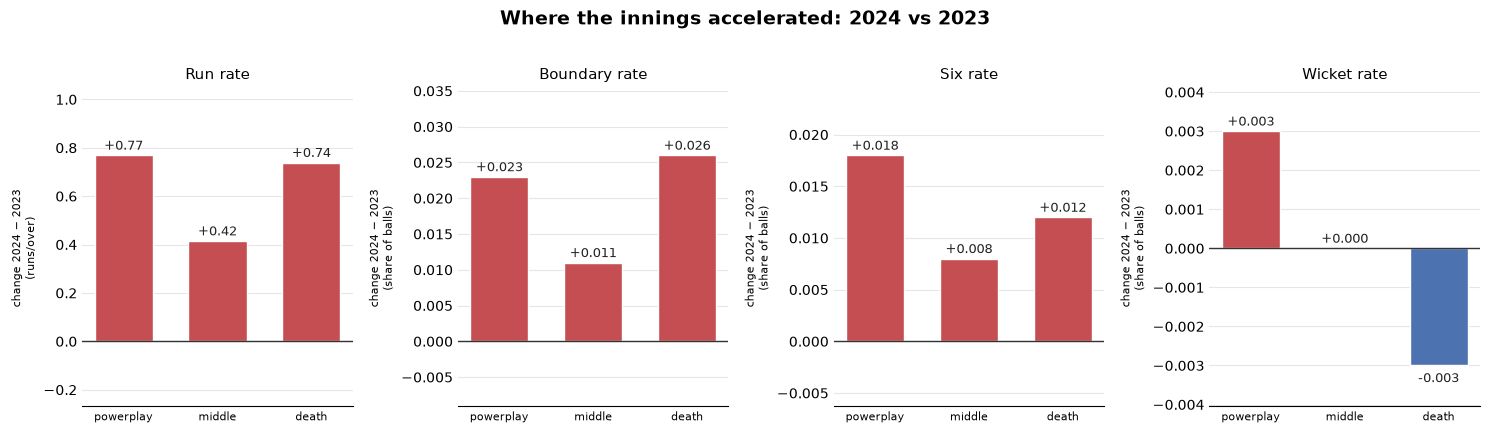

In [5]:
phase_rates, phase_frame = phases.phase_structure(df)
results_io.write_table(phase_rates.reset_index(), settings, ANALYSIS, "phase_rates", SEED, PRODUCER, EXTRA)
fig = phases.plot_phase_deltas_report(phase_rates)
results_io.write_figure(fig, settings, ANALYSIS, "phase_deltas", SEED, PRODUCER)
plt.show()

Found: the powerplay (+0.77 runs per over) and the death (+0.74) rose almost equally; the middle overs rose about half as much (+0.42). The largest relative change anywhere is the powerplay six share, from 4.6% to 6.4% of balls, about 40% higher, with the wicket rate moving from 4.1% to 4.4% of balls. The death got more explosive with a slightly lower wicket rate. The middle overs changed little on every measure.

Hands to the analyses: the phase run-rate and six-rate changes with intervals; whether the powerplay six rise came with any wicket cost; and whether "the ends accelerated while the middle lagged" survives as a shape claim once the noise in each phase is accounted for.

## What was bowled, and how it fared

Bowling is split into mix (the share of legal balls bowled by pace versus spin, per phase) and effectiveness (economy from `bowler_charge`, boundary share conceded, wicket rate), so a change reads either as "bowled differently" or "same bowling, different outcome".

=== Bowling mix: pace vs spin share of legal balls, by phase ===

year              2023   2024
phase     kind3              
powerplay other  0.001    NaN
          pace   0.797  0.858
          spin   0.202  0.142
middle    other  0.004  0.001
          pace   0.342  0.445
          spin   0.654  0.555
death     other  0.004    NaN
          pace   0.768  0.845
          spin   0.227  0.155

=== Bowling effectiveness by pace/spin and phase ===

                      legal_balls  economy  boundary_pct  wicket_rate
phase     kind3 year                                                 
powerplay pace  2023       4187.0    8.488         0.228        0.041
                2024       4326.0    9.219         0.253        0.046
          spin  2023       1063.0    8.613         0.220        0.039
                2024        714.0    9.630         0.234        0.036
middle    pace  2023       2683.0    9.057         0.184        0.047
                2024       3312.0    9.342         0.195   

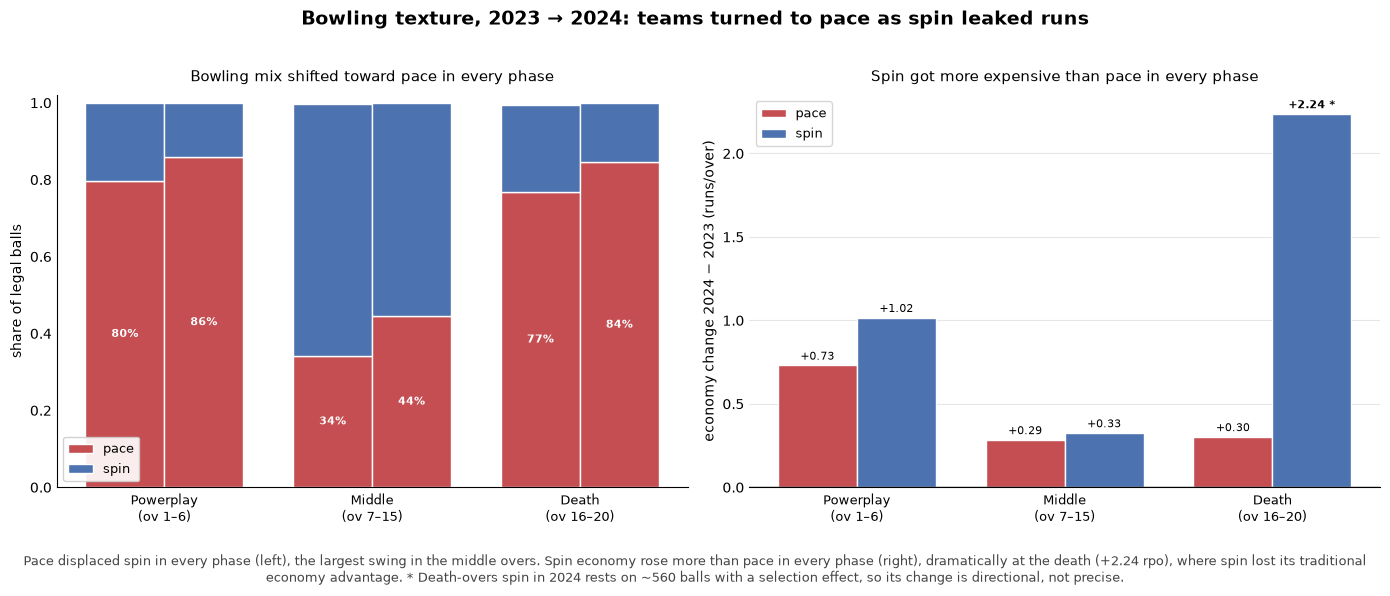

In [6]:
bowling_mix, bowling_effectiveness = phases.bowling_texture(df)
results_io.write_table(bowling_mix, settings, ANALYSIS, "bowling_mix", SEED, PRODUCER, EXTRA)
results_io.write_table(bowling_effectiveness.reset_index(), settings, ANALYSIS, "bowling_effectiveness", SEED, PRODUCER, EXTRA)
fig = phases.plot_bowling_texture(bowling_mix, bowling_effectiveness)
results_io.write_figure(fig, settings, ANALYSIS, "bowling_texture", SEED, PRODUCER)
plt.show()

Found: more pace and less spin in every phase in 2024, with the largest swing in the middle overs (pace share 34% to 45%) even though middle-overs scoring barely moved. Spin got more expensive than pace in every phase, most of all at the death, where spin went from clearly cheaper than pace (8.8 against 10.8 runs per over in 2023) to equally expensive (11.0 against 11.1). That death-overs spin figure rests on about 560 balls in 2024 and teams were choosing not to bowl it, so it is a direction rather than a precise number. In the powerplay, pace is 86% of the bowling and its economy rose by 0.73 with the boundary share conceded up from 22.8% to 25.3%: the powerplay surge was hit off pace.

Hands to the analyses: the pace-share change per phase with intervals; and, on the bowling side, whether teams spread out or converged in what they bowled.

## Where the runs went and which shots were played

Scoring geography uses the batter-relative wagon zones (left and right-handers pool directly) on balls with real placement: the share of scoring shots and of boundaries in each of the eight zones, and the zonal entropy (how evenly runs are spread; the maximum for eight zones is ln 8 = 2.08). Then the shot repertoire as the share of each tagged shot type.

In [7]:
zone_distribution, boundary_distribution, shot_table = shots.spatial_shot_evolution(df)
results_io.write_table(zone_distribution.reset_index(), settings, ANALYSIS, "zone_distribution", SEED, PRODUCER, EXTRA)
results_io.write_table(shot_table.reset_index(), settings, ANALYSIS, "shot_repertoire", SEED, PRODUCER, EXTRA)

=== Scoring-shot zone distribution by season (share of scoring shots) ===
(zones are batter-relative; 1-8 around the ground)

wagonzone_clean      1      2      3      4      5      6      7      8
year                                                                   
2023             0.056  0.099  0.206  0.154  0.136  0.192  0.102  0.055
2024             0.056  0.103  0.207  0.142  0.135  0.184  0.107  0.065

=== Boundary zone distribution by season (share of boundaries) ===

wagonzone_clean      1      2      3      4      5      6      7      8
year                                                                   
2023             0.097  0.090  0.183  0.130  0.138  0.167  0.104  0.092
2024             0.093  0.097  0.194  0.125  0.119  0.173  0.098  0.102

=== Zonal entropy of scoring shots (higher = more spread) ===
  2023: 1.984  (max ln(8) = 2.079)
  2024: 1.997  (max ln(8) = 2.079)

=== Shot repertoire share by season (top movers) ===

year            2023   2024  delta
shot  

PosixPath('/Users/madkad/dpl_2026_s1/outputs/exploration/shot_repertoire.csv')

Found: the geography did not change. Zone shares of scoring shots and of boundaries are within a point or two in every zone and the entropy is 1.98 against 2.00, so the extra boundaries were hit to the same places, more often. The shot repertoire re-weighted slightly: the pull rose most (10.7% to 12.2% of shots) and the slog fell most (5.8% to 4.1%), with small moves in hook, upper cut and the sweeps. These deltas are small and the shot column is hand-tagged, so some of this is noise.

Hands to the analyses: the controlled-power versus slog shift as a season theme, carrying the tagging caveat.

## Which teams moved with the league?

Per team: the change in run rate against the change in wicket rate ("efficient" means scoring up with wickets flat or down), the change in the share of pace bowled, the change in boundary share, and the change in middle-overs run rate. A team-season is about fourteen matches, so these are read as tiers, not fine rankings; the heatmap colours are standardised across teams and the numbers are raw changes.

=== Efficient aggression by team (scoring up, wickets flat/down = efficient) ===

                             run_rate_delta  wkt_rate_delta  efficient
team_bat                                                              
Delhi Capitals                        1.861         -0.0032       True
Kolkata Knight Riders                 1.786         -0.0091       True
Sunrisers Hyderabad                   1.467          0.0034      False
Royal Challengers Bengaluru           0.996          0.0084      False
Lucknow Super Giants                  0.569         -0.0079       True
Mumbai Indians                        0.142          0.0075      False
Punjab Kings                         -0.013         -0.0028      False
Chennai Super Kings                  -0.064          0.0018      False
Rajasthan Royals                     -0.195         -0.0074      False
Gujarat Titans                       -0.599          0.0126      False

=== Pace-share shift by team (who pivoted to pace) ===

year     

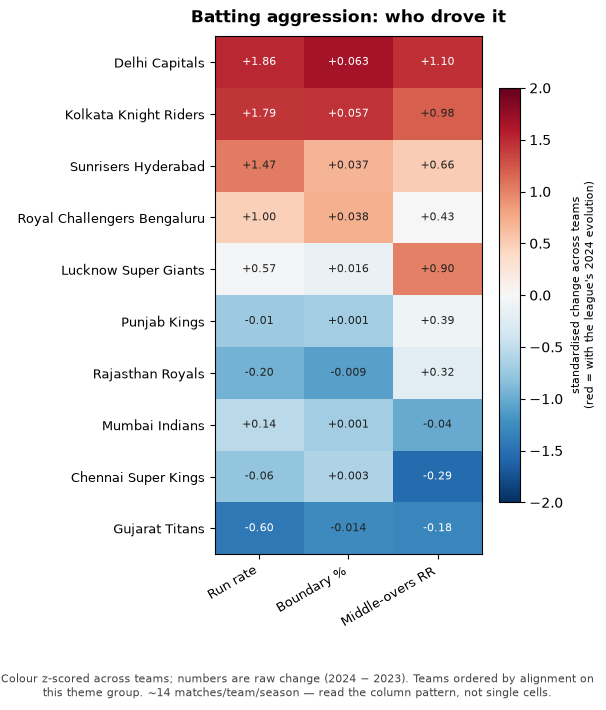

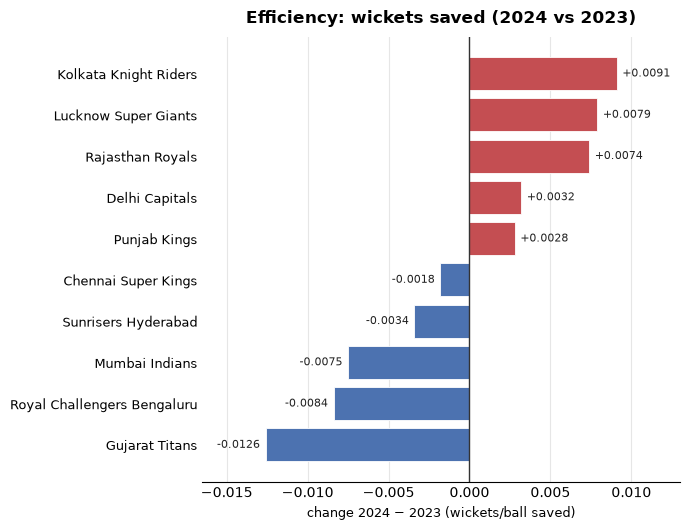

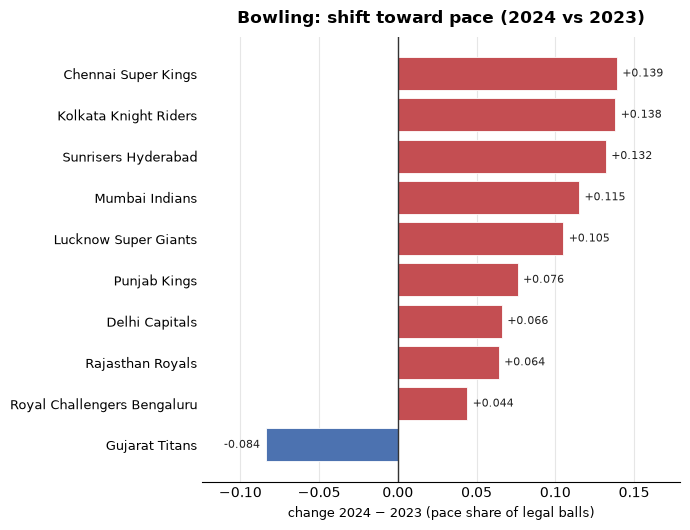

In [8]:
efficiency, pace_shift, boundary_shift, middle_shift = shots.team_theme_attribution_full(df)
for name, table in (("team_efficiency", efficiency), ("team_pace_shift", pace_shift),
                    ("team_boundary_shift", boundary_shift), ("team_middle_overs_shift", middle_shift)):
    results_io.write_table(table.reset_index(), settings, ANALYSIS, name, SEED, PRODUCER, EXTRA)
batting_themes = pd.DataFrame({"Run rate": efficiency["run_rate_delta"],
                               "Boundary %": boundary_shift["delta"],
                               "Middle-overs RR": middle_shift["delta"]})
fig = shots.team_theme_heatmap(batting_themes, "Batting aggression: who drove it",
                               value_fmt={"Run rate": "{:+.2f}", "Middle-overs RR": "{:+.2f}"})
results_io.write_figure(fig, settings, ANALYSIS, "team_batting_heatmap", SEED, PRODUCER)
plt.show()
fig = shots.team_metric_bars(-efficiency["wkt_rate_delta"], "Efficiency: wickets saved (2024 vs 2023)",
                             unit="wickets/ball saved", value_fmt="{:+.4f}")
results_io.write_figure(fig, settings, ANALYSIS, "team_wickets_saved", SEED, PRODUCER)
plt.show()
fig = shots.team_metric_bars(pace_shift["delta"], "Bowling: shift toward pace (2024 vs 2023)",
                             unit="pace share of legal balls", value_fmt="{:+.3f}")
results_io.write_figure(fig, settings, ANALYSIS, "team_pace_shift", SEED, PRODUCER)
plt.show()

Found: the league's rise was not uniform across teams. Delhi and Kolkata added about 1.8 runs per over with fewer wickets lost; Sunrisers and Bengaluru added 1.0 to 1.5 with slightly more wickets; Gujarat went the other way, scoring 0.6 fewer with more wickets lost. Every team bowled more pace, from a 14-point rise (Chennai, Kolkata, Sunrisers) down to a few points. Read as tiers, there is a clear group of movers and one counter-mover.

Hands to the analyses: whether the ten teams converged or pulled apart on these measures, phase by phase, once the noise of fourteen matches per team is accounted for; and which teams moved the spread.

## Supplementary source: Cricsheet match files and the impact substitute

The impact substitute (a twelfth player who can replace a named player once per match) is not recorded in the ball-by-ball file. Cricsheet's per-match JSON records each replacement at the delivery it occurred, with the incoming and outgoing player and the reason. The archive is cached under `data/` with its download date and checksum, so a rerun reads the same file. Match ids are the same in both sources; players are reconciled by a surname-plus-initial name key with a short fix list.

In [9]:
ARCHIVE = settings.data_dir / "cricsheet_ipl_json.zip"
archive = cricsheet.fetch_ipl_archive(ARCHIVE)
provenance = cricsheet.archive_provenance(ARCHIVE)
print("archive provenance:", provenance)
cricsheet.inspect_match_format(archive, "1359480")
cricsheet.replacement_coverage(archive)

archive provenance: {'url': 'https://cricsheet.org/downloads/ipl_json.zip', 'downloaded_utc': '2026-09-09T11:32:21+00:00', 'sha256': '841b98290a08bdf2a063a9f4d6342fb2363ff246491ed3db4c571bddb6ea2a79', 'bytes': 5180977}
Top-level keys: ['meta', 'info', 'innings']

Info keys: ['balls_per_over', 'city', 'dates', 'event', 'gender', 'match_type', 'officials', 'outcome', 'overs', 'player_of_match', 'players', 'registry', 'season', 'team_type', 'teams', 'toss', 'venue']

Players listed per team:
  Chennai Super Kings: 12 players
  Lucknow Super Giants: 12 players

Has registry: True
Innings count: 2
  innings 1 team: Chennai Super Kings; innings-level keys: ['powerplays']
    over 19: replacement: {'match': [{'in': 'A Badoni', 'out': 'Avesh Khan', 'team': 'Lucknow Super Giants', 'reason': 'impact_player'}]}
  innings 2 team: Lucknow Super Giants; innings-level keys: ['powerplays', 'target']
    over 0: replacement: {'match': [{'in': 'TU Deshpande', 'out': 'AT Rayudu', 'team': 'Chennai Super K

In [10]:
replacements = impact.extract_replacements(archive)
crosswalk = impact.build_crosswalk(df, archive)
impact_table = impact.build_impact_player_table(replacements, crosswalk, df)
impact_table.to_parquet(settings.data_path("impact_player_table"), index=False)
results_io.write_table(impact_table, settings, ANALYSIS, "impact_player_table", SEED, PRODUCER,
                       {**EXTRA, "cricsheet": provenance})
impact_table.head()

Substitution events: 277
reason
impact_player            276
concussion_substitute      1
Crosswalk rows: 307 | matched both: 257 | key collisions: 0
Impact/sub events: 277 | incoming players unmatched to dataset id: 0


,match_id,season,team,reason,innings,cricsheet_over,ball_in_over,dataset_over,deploy_ball_id,deploy_phase,player_in,in_dataset_id,player_out,out_dataset_id,subbing_team_batted_first
0,1359475,2023,Chennai Super Kings,impact_player,2,0,1,1,0.01,powerplay,TU Deshpande,822553,AT Rayudu,33141,True
1,1359475,2023,Gujarat Titans,impact_player,2,3,8,4,3.08,powerplay,B Sai Sudharsan,1151288,KS Williamson,277906,False
2,1359476,2023,Kolkata Knight Riders,impact_player,2,2,1,3,2.01,powerplay,VR Iyer,851403,CV Varun,1108375,False
3,1359476,2023,Punjab Kings,impact_player,2,0,1,1,0.01,powerplay,R Dhawan,290727,PBB Rajapaksa,342619,True
4,1359477,2023,Delhi Capitals,impact_player,1,19,1,20,19.01,death,Aman Hakim Khan,1254269,KK Ahmed,942645,False


In [11]:
impact_events = impact.impact_utilisation_eda(impact_table, df)

=== Impact-player substitutions per season ===
season
2023    139
2024    137

=== Deployment innings (1st vs 2nd) by season ===
innings   1    2
season          
2023     26  113
2024     43   94

=== Deployment phase by season (when in the innings the sub enters) ===
deploy_phase  powerplay  middle  death
season                                
2023                 83      29     27
2024                 71      29     37

=== Did the sub enter for the team's SECOND discipline? ===
Share of impact subs deployed in the 2nd innings of the match:
season
2023    0.813
2024    0.686

=== Did the impact player feature with bat or ball once subbed in? ===
         mean  sum  size
season                  
2023    0.878  122   139
2024    0.883  121   137


Found: 145 matches, every one with a replacement record; 277 substitution events, 276 impact players and one concussion substitute. Every incoming player matched to a dataset id. Impact substitutes were deployed in the first innings far more often in 2024 (43 of 137) than in 2023 (26 of 139), so the share of deployments in the second innings fell from 81% to 69%; more entered at the death in 2024 (37 against 27). About 88% of impact players then batted or bowled in both seasons.

Hands to the analyses: whether the innings reallocation is real once matches are the unit, and whether the apparent shift toward death-overs entry is a change in timing or a by-product of the innings mix.

In [12]:
rosters = impact.build_match_rosters_with_utilisation(archive, replacements, crosswalk, df,
                                                      team_canon=impact.TEAM_CANON)
rosters.to_parquet(settings.data_path("match_rosters"), index=False)
results_io.write_table(rosters, settings, ANALYSIS, "match_rosters", SEED, PRODUCER, {**EXTRA, "cricsheet": provenance})
roster_utilisation = impact.roster_utilisation_eda(rosters)

Roster rows: 3467 | players unmatched to dataset id: 0
=== Named players per team-match by role (sanity: XI≈11, impact_sub≈1) ===
              mean  min  max
role                        
impact_sub    1.00    1    2
replaced      1.00    1    2
starting_xi  10.05    9   11

=== Utilisation rate by role and season (share who batted or bowled) ===
                     rate     n
season role                    
2023   impact_sub   0.878   139
       replaced     0.892   139
       starting_xi  0.934  1490
2024   impact_sub   0.883   137
       replaced     0.912   137
       starting_xi  0.928  1425

=== Starting-XI utilisation distribution (how many of the XI feature) ===
Players from the starting XI who featured, per team-match, by season:
        count  mean   std  min  25%   50%   75%   max
season                                               
2023    148.0  9.41  0.95  5.0  9.0  10.0  10.0  11.0
2024    142.0  9.31  0.93  5.0  9.0  10.0  10.0  10.0


Found: each team-match lists twelve players, the starting eleven plus the impact substitute, with a handful of exceptions; every listed player matched to a dataset id. Utilisation is similar across roles and seasons (about 88% of impact substitutes, 90% of replaced players and 93% of the starting eleven batted or bowled), and about 9.3 to 9.4 of each starting eleven featured per match in both seasons. The rosters are written for reference; no analysis in this project uses them beyond the impact table.

## Questions handed to the analyses

1. Season contrasts with intervals: phase run rates, the powerplay six rate and its wicket cost, pace share by phase, the controlled-power shot shift (`mean_level_and_tail.ipynb`).
2. Did the ends accelerate while the middle lagged, as a shape claim rather than three separate numbers (`mean_level_and_tail.ipynb`).
3. The tail of innings totals on a population a chase cannot truncate (`mean_level_and_tail.ipynb`).
4. Did teams converge or pull apart, per phase and per discipline, and who moved the powerplay spread (`dispersion_and_attribution.ipynb`).
5. Impact-substitute reallocation and entry timing with matches as the unit (`impact_substitute.ipynb`).
6. Did the phase boundaries themselves move (`phase_boundaries.ipynb`).
7. Was the powerplay situationally safer, or just luckier (`expected_wickets.ipynb`).
8. Do the intervals used throughout cover at their stated level with this many matches (`interval_coverage.ipynb`).